In [1]:
#Basic numerical and plotting tools
import math
import time
import glob

import numpy as np
import matplotlib.pyplot as plt

#Symbolic mathematics
import sympy
from sympy import re, im, I, E, symbols, exp

#Scientific computing
from scipy.optimize import minimize
from scipy.special import pro_ang1, legendre, chebyt, chebyu

#Machine learning
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import cohen_kappa_score, f1_score

#Deep learning
import tensorflow as tf

from tensorflow.keras.layers import (
    Dense, Flatten, Cropping1D, Concatenate, MaxPooling1D,
    Dropout, Reshape, Conv1D, BatchNormalization, Activation,
    AveragePooling1D, GlobalAveragePooling1D, Lambda, Input,
    Add, UpSampling1D, Multiply
)

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras import losses, backend as K

from tensorflow.keras.losses import (
    Hinge, binary_crossentropy, categorical_crossentropy
)

from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, TensorBoard,
    ReduceLROnPlateau, LearningRateScheduler, Callback
)

from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.optimizers import Adam, RMSprop, SGD


In [2]:
#Experiment parameters
Nsamples = [1000]
Ntest = 1000

Para_slep = np.linspace(5, 25, 10).astype(int)
total_runs = 20

In [3]:
#Generate random sample points uniformly on [-1, 1]
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    if isinstance(n_samples, (list, np.ndarray)):
        n_samples = n_samples[0]

    n_samples = int(n_samples)
    return rng.uniform(-1, 1, n_samples)

In [4]:
#Define the target function g(x) = exp(-x^2 / 2)
def target_function(x):
    return np.exp(-0.5 * x**2)

In [5]:

#Evaluate the normalized Chebyshev polynomial of the first kind
def normalized_chebyshev(x, degree):
    normalization = (
        np.sqrt(np.pi)
        if degree == 0
        else np.sqrt(np.pi / 2)
    )
    return chebyt(degree)(x) / normalization



In [6]:
#Build the matrix for the least-squares approximation

def build_chebyshev_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_chebyshev(samples[k], j)

    return A

RMSE: 3.206657e-04 | Progress: 0.5% | Estimated time remaining: 230.0 s
RMSE: 9.947348e-06 | Progress: 1.0% | Estimated time remaining: 114.5 s
RMSE: 2.515054e-07 | Progress: 1.5% | Estimated time remaining: 76.0 s
RMSE: 5.124697e-09 | Progress: 2.0% | Estimated time remaining: 56.7 s
RMSE: 9.354784e-11 | Progress: 2.5% | Estimated time remaining: 45.1 s
RMSE: 1.503857e-12 | Progress: 3.0% | Estimated time remaining: 37.4 s
RMSE: 2.033735e-14 | Progress: 3.5% | Estimated time remaining: 31.9 s
RMSE: 7.482845e-15 | Progress: 4.0% | Estimated time remaining: 27.8 s
RMSE: 3.171260e-15 | Progress: 4.5% | Estimated time remaining: 24.6 s
RMSE: 3.107921e-15 | Progress: 5.0% | Estimated time remaining: 22.0 s
RMSE: 3.205148e-04 | Progress: 5.5% | Estimated time remaining: 40.7 s
RMSE: 9.983332e-06 | Progress: 6.0% | Estimated time remaining: 37.1 s
RMSE: 2.516312e-07 | Progress: 6.5% | Estimated time remaining: 34.1 s
RMSE: 5.150227e-09 | Progress: 7.0% | Estimated time remaining: 31.5 s
RMSE

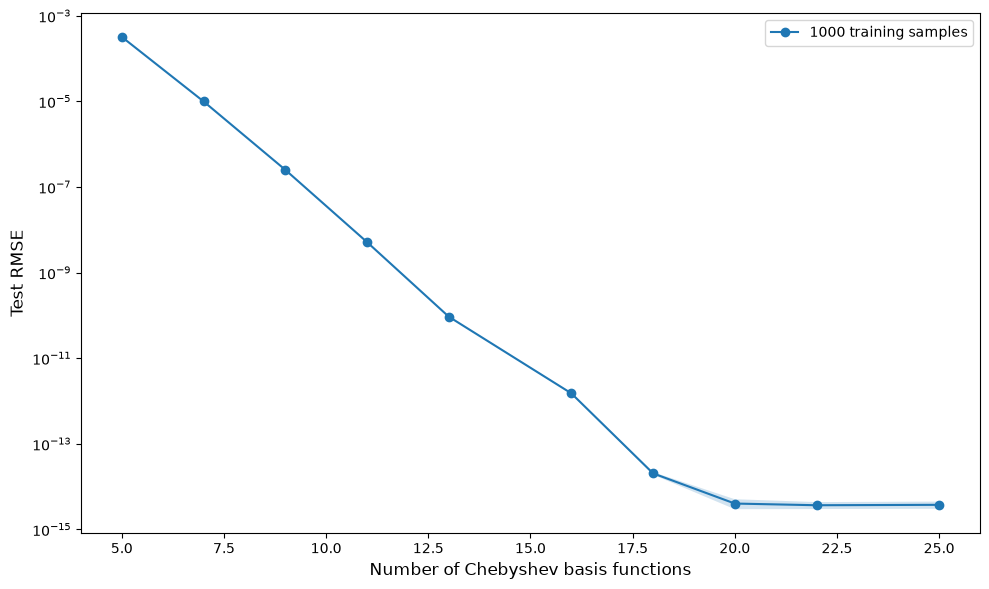

In [7]:


# Run the Chebyshev least-squares experiment

n_basis_values = Para_slep
n_sample_values = Nsamples

# Store test RMSE for each basis size, sample size, and run.
rmse_chebyshev = np.zeros(
    (len(n_basis_values), len(n_sample_values), total_runs)
)

# Use the same independent test set for every run and basis size.
test_samples = generate_samples(Ntest)
test_values = target_function(test_samples)
test_matrix = build_chebyshev_matrix(
    test_samples, max(n_basis_values)
)

start_time = time.time()
total_iterations = total_runs * len(n_basis_values) * len(n_sample_values)
counter = 0

for run in range(total_runs):
    # Generate the largest training set once per run.
    train_samples = generate_samples(max(n_sample_values))
    train_values = target_function(train_samples)

    # Build the largest training matrix once per run.
    train_matrix = build_chebyshev_matrix(
        train_samples, max(n_basis_values)
    )

    for i, n_basis in enumerate(n_basis_values):
        for j, n_samples in enumerate(n_sample_values):
            # Select the required numbers of samples and basis functions.
            A = train_matrix[:n_samples, :n_basis]
            y = train_values[:n_samples]
            A_test = test_matrix[:, :n_basis]

            # Solve the least-squares problem directly.
            coefficients, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

            # Evaluate the approximation on the test set.
            predictions = A_test @ coefficients

            # Calculate root mean squared test error (RMSE).
            rmse = np.sqrt(np.mean((predictions - test_values) ** 2))
            rmse_chebyshev[i, j, run] = rmse

            # Report progress.
            counter += 1
            elapsed = time.time() - start_time
            remaining = elapsed / counter * (total_iterations - counter)

            print(
                f"RMSE: {rmse:.6e} | "
                f"Progress: {100 * counter / total_iterations:.1f}% | "
                f"Estimated time remaining: {remaining:.1f} s"
            )

# Summarize results across independent runs.
mean_rmse = np.mean(rmse_chebyshev, axis=2)
std_rmse = np.std(rmse_chebyshev, axis=2)

# Plot test RMSE against the number of basis functions.
plt.figure(figsize=(10, 6))

for j, n_samples in enumerate(n_sample_values):
    mean = mean_rmse[:, j]
    std = std_rmse[:, j]

    plt.semilogy(
        n_basis_values,
        mean,
        marker="o",
        label=f"{n_samples} training samples"
    )

    # Shaded region: mean RMSE ± one standard deviation.
    lower = np.maximum(mean - std, np.finfo(float).tiny)
    upper = mean + std

    plt.fill_between(
        n_basis_values, lower, upper, alpha=0.2
    )

plt.xlabel("Number of Chebyshev basis functions", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig("error_vs_basis_size.pdf", bbox_inches="tight")
plt.show()


In [8]:
#Evaluate the normalized Legendre polynomial of degree j

def normalized_legendre(x, degree):
    polynomial = legendre(degree)(x)

    normalization = np.sqrt(2 / (2 * degree + 1))

    return polynomial / normalization


In [9]:
#Build the matrix for the least-squares approximation using normalized Legendre polynomials

def build_legendre_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_legendre(samples[k], j)

    return A

RMSE: 3.184497e-04 | Progress: 0.5% | Estimated time remaining: 419.6 s
RMSE: 9.897230e-06 | Progress: 1.0% | Estimated time remaining: 208.8 s
RMSE: 2.531742e-07 | Progress: 1.5% | Estimated time remaining: 138.5 s
RMSE: 5.370672e-09 | Progress: 2.0% | Estimated time remaining: 103.3 s
RMSE: 9.538764e-11 | Progress: 2.5% | Estimated time remaining: 82.3 s
RMSE: 1.541236e-12 | Progress: 3.0% | Estimated time remaining: 68.2 s
RMSE: 2.178882e-14 | Progress: 3.5% | Estimated time remaining: 58.2 s
RMSE: 1.464666e-15 | Progress: 4.0% | Estimated time remaining: 50.6 s
RMSE: 4.058443e-15 | Progress: 4.5% | Estimated time remaining: 44.8 s
RMSE: 7.291216e-16 | Progress: 5.0% | Estimated time remaining: 40.1 s
RMSE: 3.169192e-04 | Progress: 5.5% | Estimated time remaining: 73.6 s
RMSE: 9.845100e-06 | Progress: 6.0% | Estimated time remaining: 67.1 s
RMSE: 2.524095e-07 | Progress: 6.5% | Estimated time remaining: 61.6 s
RMSE: 5.345463e-09 | Progress: 7.0% | Estimated time remaining: 56.9 s
RM

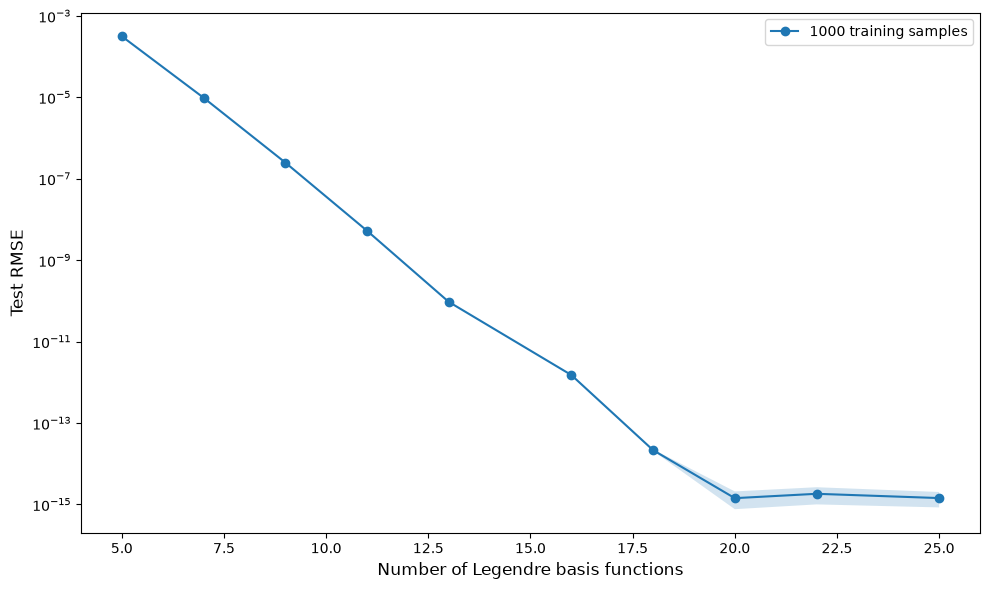

In [10]:

#Run the Legendre least-squares experiment

n_basis_values = Para_slep
n_sample_values = Nsamples

# Store test RMSE for each basis size, sample size, and run.
rmse_legendre = np.zeros(
    (len(n_basis_values), len(n_sample_values), total_runs)
)

# Use the same independent test set for every run and basis size.
test_samples = generate_samples(Ntest)
test_values = target_function(test_samples)
test_matrix = build_legendre_matrix(
    test_samples, max(n_basis_values)
)

start_time = time.time()
total_iterations = total_runs * len(n_basis_values) * len(n_sample_values)
counter = 0

for run in range(total_runs):
    # Generate the largest training set once per run.
    train_samples = generate_samples(max(n_sample_values))
    train_values = target_function(train_samples)

    # Build the largest Legendre matrix once per run.
    train_matrix = build_legendre_matrix(
        train_samples, max(n_basis_values)
    )

    for i, n_basis in enumerate(n_basis_values):
        for j, n_samples in enumerate(n_sample_values):
            A = train_matrix[:n_samples, :n_basis]
            y = train_values[:n_samples]
            A_test = test_matrix[:, :n_basis]

            # Solve the least-squares problem directly.
            coefficients, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

            # Evaluate the approximation on the test set.
            predictions = A_test @ coefficients

            # Calculate root mean squared test error (RMSE).
            rmse = np.sqrt(np.mean((predictions - test_values) ** 2))
            rmse_legendre[i, j, run] = rmse

            # Report progress.
            counter += 1
            elapsed = time.time() - start_time
            remaining = elapsed / counter * (total_iterations - counter)

            print(
                f"RMSE: {rmse:.6e} | "
                f"Progress: {100 * counter / total_iterations:.1f}% | "
                f"Estimated time remaining: {remaining:.1f} s"
            )

# Summarize results across independent runs.
mean_rmse = np.mean(rmse_legendre, axis=2)
std_rmse = np.std(rmse_legendre, axis=2)

# Plot test RMSE against the number of Legendre basis functions.
plt.figure(figsize=(10, 6))

for j, n_samples in enumerate(n_sample_values):
    mean = mean_rmse[:, j]
    std = std_rmse[:, j]

    plt.semilogy(
        n_basis_values,
        mean,
        marker="o",
        label=f"{n_samples} training samples"
    )

    # Shaded region: mean RMSE ± one standard deviation.
    lower = np.maximum(mean - std, np.finfo(float).tiny)
    upper = mean + std

    plt.fill_between(
        n_basis_values, lower, upper, alpha=0.2
    )

plt.xlabel("Number of Legendre basis functions", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig("error_vs_legendre_basis_size.pdf", bbox_inches="tight")
plt.show()



In [11]:
#Calculate the normalization quantity for a Slepian function

def slepian_normalization(degree, bandwidth):
    alpha = 0
    theta = np.linspace(-1, 1, 200)

    pswf_values = pro_ang1(alpha, degree, bandwidth, theta)
    pswf_values = pswf_values[0]

    pswf_values = pswf_values[1:199]
    # normalization = np.linalg.norm(pswf_values) / np.sqrt(len(theta) - 1)
    ##check on the normalization method##
    normalization = np.sqrt(0.5 * np.trapezoid(np.abs(pswf_values)**2, x=theta[1:-1]))

    return normalization


slepian_norms = np.zeros(Para_slep[-1])

for degree in range(Para_slep[-1]):
    slepian_norms[degree] = slepian_normalization(degree, 4)

In [12]:
#Evaluate the normalized Slepian function of degree j and bandwidth c

def normalized_slepian(x, degree, bandwidth):
    alpha = 0

    pswf_values = pro_ang1(alpha, degree, bandwidth, x)
    pswf_values = pswf_values[0]

    normalization = slepian_norms[degree]

    return pswf_values / normalization

In [13]:

#Build the matrix for the least-squares approximation using normalized Slepian functions
def build_slepian_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        for k in range(len(samples)):
            A[k, j] = normalized_slepian(samples[k], j, 4)

    return A


RMSE: 4.353294e-04 | Progress: 0.5% | Estimated time remaining: 280.5 s
RMSE: 3.345770e-06 | Progress: 1.0% | Estimated time remaining: 139.6 s
RMSE: 1.168943e-08 | Progress: 1.5% | Estimated time remaining: 92.6 s
RMSE: 7.144876e-11 | Progress: 2.0% | Estimated time remaining: 69.1 s
RMSE: 7.617647e-13 | Progress: 2.5% | Estimated time remaining: 55.0 s
RMSE: 1.387386e-14 | Progress: 3.0% | Estimated time remaining: 45.6 s
RMSE: 4.523529e-16 | Progress: 3.5% | Estimated time remaining: 38.9 s
RMSE: 7.615110e-16 | Progress: 4.0% | Estimated time remaining: 33.9 s
RMSE: 1.224727e-15 | Progress: 4.5% | Estimated time remaining: 29.9 s
RMSE: 6.379968e-16 | Progress: 5.0% | Estimated time remaining: 26.8 s
RMSE: 4.299217e-04 | Progress: 5.5% | Estimated time remaining: 49.2 s
RMSE: 3.302201e-06 | Progress: 6.0% | Estimated time remaining: 44.9 s
RMSE: 1.149552e-08 | Progress: 6.5% | Estimated time remaining: 41.2 s
RMSE: 7.003272e-11 | Progress: 7.0% | Estimated time remaining: 38.1 s
RMSE

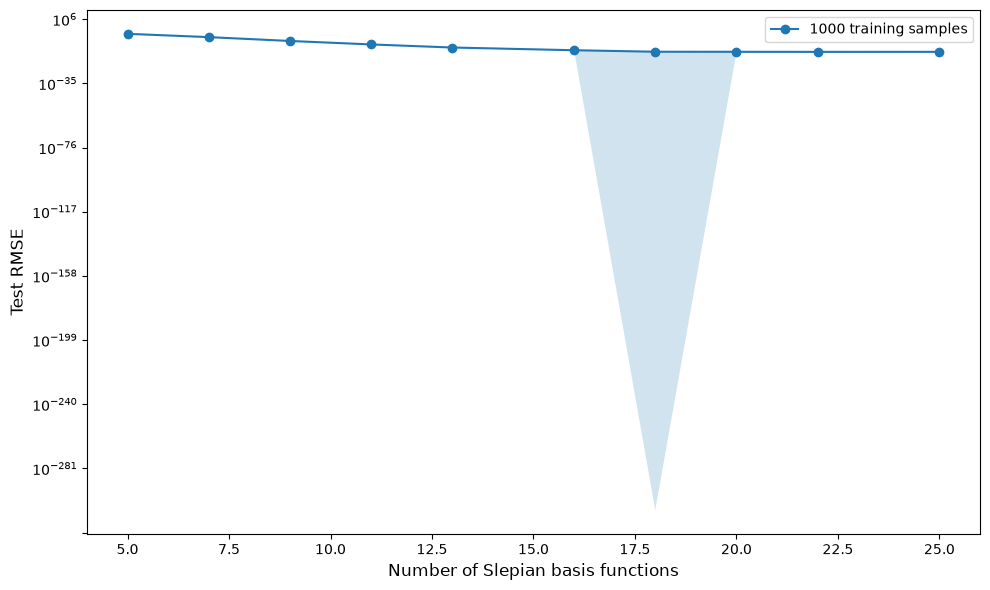

In [14]:

#Run the Slepian least-squares experiment

n_basis_values = Para_slep
n_sample_values = Nsamples
bandwidth = 4

#Store test RMSE for each basis size, sample size, and independent run.
rmse_slepian = np.zeros(
    (len(n_basis_values), len(n_sample_values), total_runs)
)

#Use the same independent test set for every run and basis size.
test_samples = generate_samples(Ntest)
test_values = target_function(test_samples)
test_matrix = build_slepian_matrix(
    test_samples, max(n_basis_values)
)

start_time = time.time()
total_iterations = total_runs * len(n_basis_values) * len(n_sample_values)
counter = 0

for run in range(total_runs):
    #Generate the largest training set once per run.
    train_samples = generate_samples(max(n_sample_values))
    train_values = target_function(train_samples)

    #Build the largest Slepian matrix once per run.
    train_matrix = build_slepian_matrix(
        train_samples, max(n_basis_values)
    )

    for i, n_basis in enumerate(n_basis_values):
        for j, n_samples in enumerate(n_sample_values):
            #Select the required numbers of samples and basis functions.
            A = train_matrix[:n_samples, :n_basis]
            y = train_values[:n_samples]
            A_test = test_matrix[:, :n_basis]

            #Solve the least-squares problem directly.
            coefficients, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

            #Evaluate the approximation on the test set.
            predictions = A_test @ coefficients

            #Calculate root mean squared test error (RMSE).
            rmse = np.sqrt(np.mean((predictions - test_values) ** 2))
            rmse_slepian[i, j, run] = rmse

            #Report progress.
            counter += 1
            elapsed = time.time() - start_time
            remaining = elapsed / counter * (total_iterations - counter)

            print(
                f"RMSE: {rmse:.6e} | "
                f"Progress: {100 * counter / total_iterations:.1f}% | "
                f"Estimated time remaining: {remaining:.1f} s"
            )

#Summarize results across independent runs.
mean_rmse = np.mean(rmse_slepian, axis=2)
std_rmse = np.std(rmse_slepian, axis=2)

#Plot test RMSE against the number of Slepian basis functions.
plt.figure(figsize=(10, 6))

for j, n_samples in enumerate(n_sample_values):
    mean = mean_rmse[:, j]
    std = std_rmse[:, j]

    plt.semilogy(
        n_basis_values,
        mean,
        marker="o",
        label=f"{n_samples} training samples"
    )

    #Shaded region: mean RMSE ± one standard deviation.
    lower = np.maximum(mean - std, np.finfo(float).tiny)
    upper = mean + std

    plt.fill_between(
        n_basis_values, lower, upper, alpha=0.2
    )

plt.xlabel("Number of Slepian basis functions", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig("error_vs_slepian_basis_size.pdf", bbox_inches="tight")
plt.show()


In [15]:

# Run and compare the Chebyshev, Legendre, and Slepian experiments

n_basis_values = Para_slep
n_sample_values = Nsamples
bandwidth = 4

# Store test RMSE for each basis size, sample size, and run.
rmse_chebyshev = np.zeros(
    (len(n_basis_values), len(n_sample_values), total_runs)
)
rmse_legendre = np.zeros_like(rmse_chebyshev)
rmse_slepian = np.zeros_like(rmse_chebyshev)

# Use one fixed, independent test set for all three bases and all runs.
test_samples = generate_samples(Ntest)
test_values = target_function(test_samples)

test_matrices = {
    "Chebyshev": build_chebyshev_matrix(
        test_samples, max(n_basis_values)
    ),
    "Legendre": build_legendre_matrix(
        test_samples, max(n_basis_values)
    ),
    "Slepian": build_slepian_matrix(
        test_samples, max(n_basis_values)
    ),
}

# Associate each basis with its test matrix and result array.
experiments = [
    ("Chebyshev", build_chebyshev_matrix, test_matrices["Chebyshev"],
     rmse_chebyshev),
    ("Legendre", build_legendre_matrix, test_matrices["Legendre"],
     rmse_legendre),
    ("Slepian", build_slepian_matrix, test_matrices["Slepian"],
     rmse_slepian),
]

start_time = time.time()
total_iterations = (
    total_runs * len(n_basis_values) * len(n_sample_values) * len(experiments)
)
counter = 0

for run in range(total_runs):
    # Generate one training set per run, shared by all three bases.
    train_samples = generate_samples(max(n_sample_values))
    train_values = target_function(train_samples)

    for basis_name, build_matrix, test_matrix, results in experiments:
        # Build the training matrix for this basis.
        train_matrix = build_matrix(
            train_samples, max(n_basis_values)
        )

        for i, n_basis in enumerate(n_basis_values):
            for j, n_samples in enumerate(n_sample_values):
                # Select the required samples and basis functions.
                A = train_matrix[:n_samples, :n_basis]
                y = train_values[:n_samples]
                A_test = test_matrix[:, :n_basis]

                # Solve the least-squares problem directly.
                coefficients, _, _, _ = np.linalg.lstsq(
                    A, y, rcond=None
                )

                # Evaluate on the shared test set.
                predictions = A_test @ coefficients

                # Calculate root mean squared test error (RMSE).
                rmse = np.sqrt(
                    np.mean((predictions - test_values) ** 2)
                )
                results[i, j, run] = rmse

                # Report progress.
                counter += 1
                elapsed = time.time() - start_time
                remaining = (
                    elapsed / counter * (total_iterations - counter)
                )

                print(
                    f"{basis_name} | "
                    f"RMSE: {rmse:.6e} | "
                    f"Progress: {100 * counter / total_iterations:.1f}% | "
                    f"Estimated time remaining: {remaining:.1f} s"
                )

print("All three experiments completed.")

# Summarize each experiment across independent runs.
mean_rmse_chebyshev = np.mean(rmse_chebyshev, axis=2)
std_rmse_chebyshev = np.std(rmse_chebyshev, axis=2)

mean_rmse_legendre = np.mean(rmse_legendre, axis=2)
std_rmse_legendre = np.std(rmse_legendre, axis=2)

mean_rmse_slepian = np.mean(rmse_slepian, axis=2)
std_rmse_slepian = np.std(rmse_slepian, axis=2)


Chebyshev | RMSE: 3.145605e-04 | Progress: 0.2% | Estimated time remaining: 676.3 s
Chebyshev | RMSE: 9.749980e-06 | Progress: 0.3% | Estimated time remaining: 337.7 s
Chebyshev | RMSE: 2.458207e-07 | Progress: 0.5% | Estimated time remaining: 224.8 s
Chebyshev | RMSE: 5.015158e-09 | Progress: 0.7% | Estimated time remaining: 168.3 s
Chebyshev | RMSE: 9.054897e-11 | Progress: 0.8% | Estimated time remaining: 134.4 s
Chebyshev | RMSE: 1.402825e-12 | Progress: 1.0% | Estimated time remaining: 111.9 s
Chebyshev | RMSE: 2.017179e-14 | Progress: 1.2% | Estimated time remaining: 95.7 s
Chebyshev | RMSE: 3.317513e-15 | Progress: 1.3% | Estimated time remaining: 83.6 s
Chebyshev | RMSE: 4.442312e-15 | Progress: 1.5% | Estimated time remaining: 74.2 s
Chebyshev | RMSE: 3.047838e-15 | Progress: 1.7% | Estimated time remaining: 66.7 s
Legendre | RMSE: 3.145605e-04 | Progress: 1.8% | Estimated time remaining: 176.2 s
Legendre | RMSE: 9.749980e-06 | Progress: 2.0% | Estimated time remaining: 161.2 

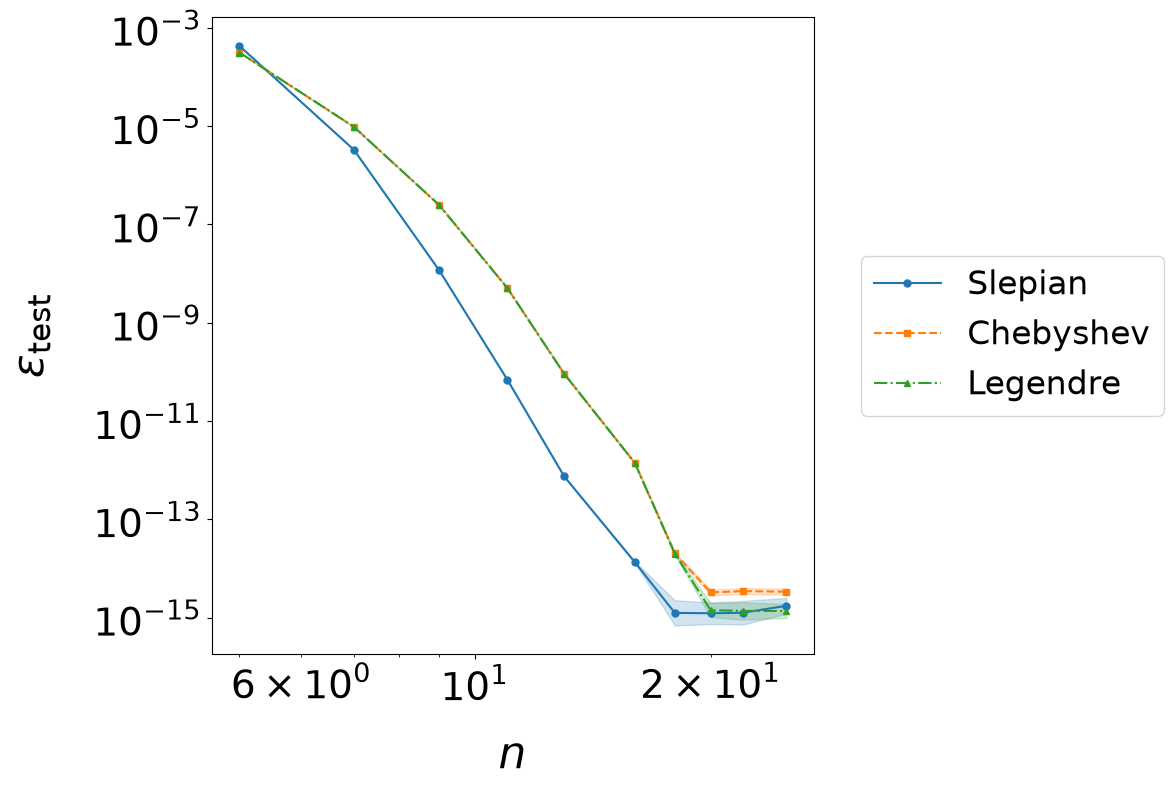

In [16]:
# Plot test RMSE versus basis size

plt.figure(figsize=(12, 8))

# Mean RMSE across independent runs
results_mean_cheby = np.mean(rmse_chebyshev, axis=2)
results_mean_leg = np.mean(rmse_legendre, axis=2)
results_mean_slep = np.mean(rmse_slepian, axis=2)

# Relative standard deviation across independent runs
results_lower_cheby = np.std(rmse_chebyshev, axis=2) / results_mean_cheby
results_lower_leg = np.std(rmse_legendre, axis=2) / results_mean_leg
results_lower_slep = np.std(rmse_slepian, axis=2) / results_mean_slep

for i in range(len(n_sample_values)):

    # Slepian basis: blue, solid
    plt.loglog(
        n_basis_values, results_mean_slep[:, i],
        color='tab:blue', linestyle='-', marker='o',
        markersize=5, label="Slepian"
    )
    plt.fill_between(
        n_basis_values,
        results_mean_slep[:, i] / (1 + results_lower_slep[:, i]),
        results_mean_slep[:, i] * (1 + results_lower_slep[:, i]),
        color='tab:blue', alpha=0.2
    )

    # Chebyshev basis: orange, dashed
    plt.loglog(
        n_basis_values, results_mean_cheby[:, i],
        color='tab:orange', linestyle='--', marker='s',
        markersize=5, label="Chebyshev"
    )
    plt.fill_between(
        n_basis_values,
        results_mean_cheby[:, i] / (1 + results_lower_cheby[:, i]),
        results_mean_cheby[:, i] * (1 + results_lower_cheby[:, i]),
        color='tab:orange', alpha=0.2
    )

    # Legendre basis: green, dash-dot
    plt.loglog(
        n_basis_values, results_mean_leg[:, i],
        color='tab:green', linestyle='-.', marker='^',
        markersize=5, label="Legendre"
    )
    plt.fill_between(
        n_basis_values,
        results_mean_leg[:, i] / (1 + results_lower_leg[:, i]),
        results_mean_leg[:, i] * (1 + results_lower_leg[:, i]),
        color='tab:green', alpha=0.2
    )

plt.xlabel(r'$n$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{\mathrm{test}}$', fontsize=32, labelpad=28)

plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("error_vs_basis_comparison.pdf", bbox_inches="tight")
plt.show()
